# Visualizing Cycle Checking Strategies: Maze

Cycles are an issue with DFS and we need cycle checking.



# Code

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


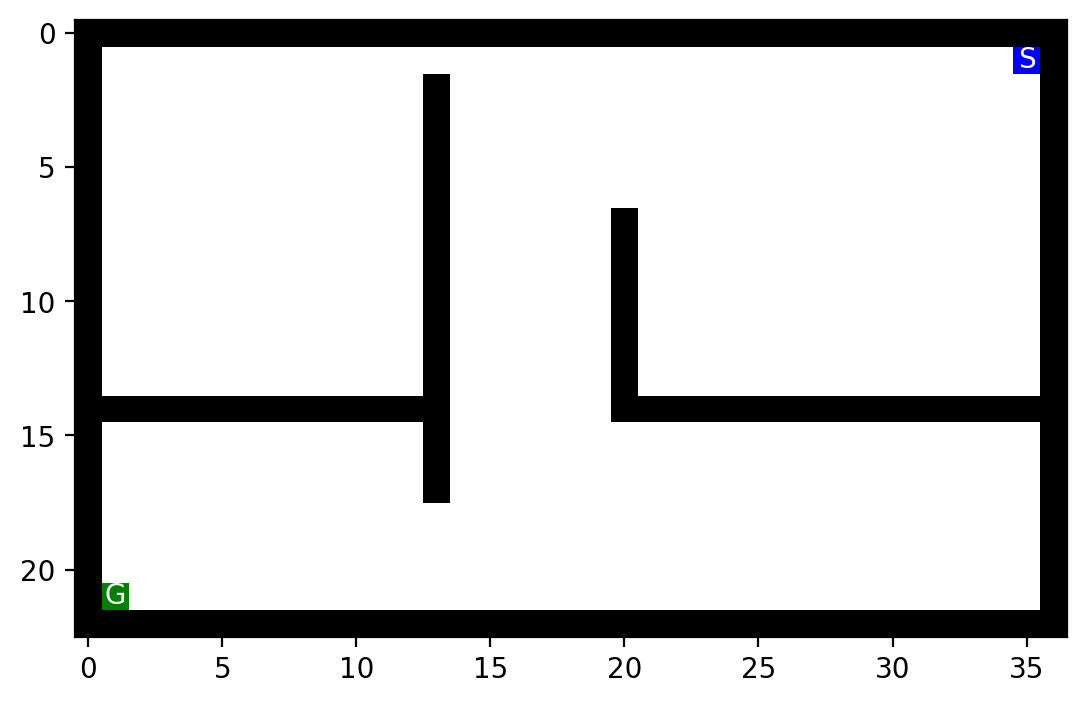

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np


#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts

# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)


## DFS Cycle checking option 1: Check the path

Do not expand nodes for states that are already in the current path. It works like this:

* Expand puts all new states into the frontier.
* When a state is taken from the frontier then we check if we already have a node for this state in the current path from the root node. If so,
then we ignore the state and pick the next one from the frontier. 
hen we try to add a frontier node to the current path then
we check if the state already exists in the path. 

Turns out that this does not manage the frontier well because there are cases where the same state gets added multiple times to the frontier leading to clearing 
space and then re-exploring it over and over again.


In [3]:
%time result = ts.DFS(maze, vis = False, animation = True, max_tries=500, frontier_option = 3)

ts.animate_maze(result)

CPU times: user 30.7 ms, sys: 0 ns, total: 30.7 ms
Wall time: 32.8 ms
No solution found.


**Bài làm – Phương án 1 (kiểm tra đường đi, `frontier_option = 3`).** Trong 500 lần lặp DFS **không tìm được lời giải**. Khi mở rộng một nút, mọi trạng thái con chưa nằm trên đường đi hiện tại đều được thêm vào frontier, kể cả khi trạng thái đó đã có trong frontier, nên cùng một ô xuất hiện nhiều lần (tối đa 17 bản sao). Khi quay lui, các ô của nhánh đã duyệt bị quên và lại được khám phá lại: 500 lần mở rộng nhưng chỉ 179 trạng thái khác nhau (321 lần mở rộng lại), frontier lớn nhất = 155. Các ô đỏ (đường đi) nhìn như đặc kín cả căn phòng bên trái nhưng vẫn còn nhiều ô cam (frontier) chưa xử lý.

The room looks solid red, but there are still some of the red points left in the frontier!

## DFS Cycle checking option 2: Check the path + don't add states that are already in the frontier a second time.

This unfortunately does not work and produces still an infinite loop if there are any open spaces in the maze!

In [4]:
%time result = ts.DFS(maze, animation = True, max_tries = 500, frontier_option = 2)

ts.animate_maze(result)

CPU times: user 26.6 ms, sys: 67 μs, total: 26.6 ms
Wall time: 27.6 ms
No solution found.


**Bài làm – Phương án 2 (không thêm lại trạng thái đang có trong frontier, `frontier_option = 2`).** Vẫn **không tìm được lời giải** sau 500 lần lặp. Frontier gọn hơn (lớn nhất = 91, không còn bản sao) nhưng mục cũ của trạng thái vẫn nằm sâu trong stack với đường đi cũ; khi một nhánh bị bỏ khỏi bộ nhớ (ô chuyển trắng) các ô cam còn sót lại khiến DFS quay lại duyệt lại cùng vùng: 500 lần mở rộng, chỉ 117 trạng thái khác nhau (383 lần mở rộng lại). Khi tăng giới hạn lên 100.000 lần lặp vẫn không giải được.

Note that there are still frontier entires (orange squares) left when DFS removed a completed branch from memory (squares that turn white). This is a problem, since DFS will explore them again leading to an infinite loop.



## DFS Cycle checking option 3: Check the path + fix the frontier by moving found states to the top of the frontier stack

Increasing the priority of a frontier entry when we see it again solves this issue (i.e., remove it from the stack and put it again on the top). 
Note that there are no orange squares left when DFS removes a path from memory so it knows that this part of the maze is done.

In [5]:
%time result = ts.DFS(maze, vis = False, animation = True, max_tries=500, frontier_option = 1)

ts.animate_maze(result)

CPU times: user 8.4 ms, sys: 0 ns, total: 8.4 ms
Wall time: 8.46 ms
Path length: 54
Reached squares: 211
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S']


**Bài làm – Phương án 3 (đưa trạng thái tìm thấy lại lên đầu stack, `frontier_option = 1`).** **Tìm được lời giải sau 212 lần lặp** (đường đi dài 54). Mỗi trạng thái có tối đa một mục trong frontier (bản mới nhất, đúng thứ tự DFS) nên khi DFS bỏ một nhánh khỏi bộ nhớ thì không còn ô cam nào của vùng đó: 211 lần mở rộng = 211 trạng thái khác nhau (0 lần mở rộng lại), frontier lớn nhất = 64.

# Bài 7 – So sánh ba phương án (chạy code)
So sánh số lần lặp, kích thước frontier và hiện tượng lặp trạng thái trên `open_maze`, thứ tự `NESW`. `frontier_option`: 3 = Phương án 1, 2 = Phương án 2, 1 = Phương án 3.

In [6]:
import random
names = {3: "Phương án 1 (kiểm tra đường đi)", 2: "Phương án 2 (+ không thêm trùng frontier)", 1: "Phương án 3 (+ đưa lên đầu stack)"}
ts.set_order("NESW")
for cap in [500, 5000, 100000]:
    print(f"\n=== Giới hạn {cap} lần lặp ===")
    print(f"{'':42}{'giải?':>7}{'lặp':>8}{'maxFr':>7}{'#TT khác':>10}{'mở rộng lại':>13}{'trùng FR':>10}{'sâu nhất':>10}{'dài ĐĐ':>8}")
    for opt in (3, 2, 1):
        s = ts.DFS(maze, max_tries=cap, frontier_option=opt)['stats']
        print(f"{names[opt]:42}{str(s['solved']):>7}{s['iterations']:>8}{s['max_frontier']:>7}{s['distinct_states']:>10}"
              f"{s['reexpansions']:>13}{s['max_dup_in_frontier']:>10}{s['max_depth']:>10}{str(s['path_len']):>8}")


=== Giới hạn 500 lần lặp ===
                                            giải?     lặp  maxFr  #TT khác  mở rộng lại  trùng FR  sâu nhất  dài ĐĐ
Phương án 1 (kiểm tra đường đi)             False     500    155       179          321        17       178    None
Phương án 2 (+ không thêm trùng frontier)   False     500     91       117          383         0       112    None
Phương án 3 (+ đưa lên đầu stack)            True     212     64       211            0         0       178      54

=== Giới hạn 5000 lần lặp ===
                                            giải?     lặp  maxFr  #TT khác  mở rộng lại  trùng FR  sâu nhất  dài ĐĐ
Phương án 1 (kiểm tra đường đi)             False    5000    155       179         4821        17       178    None


Phương án 2 (+ không thêm trùng frontier)   False    5000     91       120         4880         0       115    None
Phương án 3 (+ đưa lên đầu stack)            True     212     64       211            0         0       178      54

=== Giới hạn 100000 lần lặp ===
                                            giải?     lặp  maxFr  #TT khác  mở rộng lại  trùng FR  sâu nhất  dài ĐĐ


Phương án 1 (kiểm tra đường đi)             False  100000    155       179        99821        23       178    None


Phương án 2 (+ không thêm trùng frontier)   False  100000     92       124        99876         0       121    None
Phương án 3 (+ đưa lên đầu stack)            True     212     64       211            0         0       178      54


**Giải thích các cột:** *lặp* = số lần lấy một nút khỏi frontier; *maxFr* = kích thước frontier lớn nhất; *#TT khác* = số trạng thái khác nhau đã được mở rộng; *mở rộng lại* = số lần mở rộng − #TT khác (hiện tượng lặp trạng thái); *trùng FR* = số mục thừa (cùng trạng thái) lớn nhất trong frontier; *dài ĐĐ* = độ dài đường đi tìm được.

### Hình: trạng thái của ba phương án tại lần lặp thứ 500 (hoặc khi tìm thấy G)

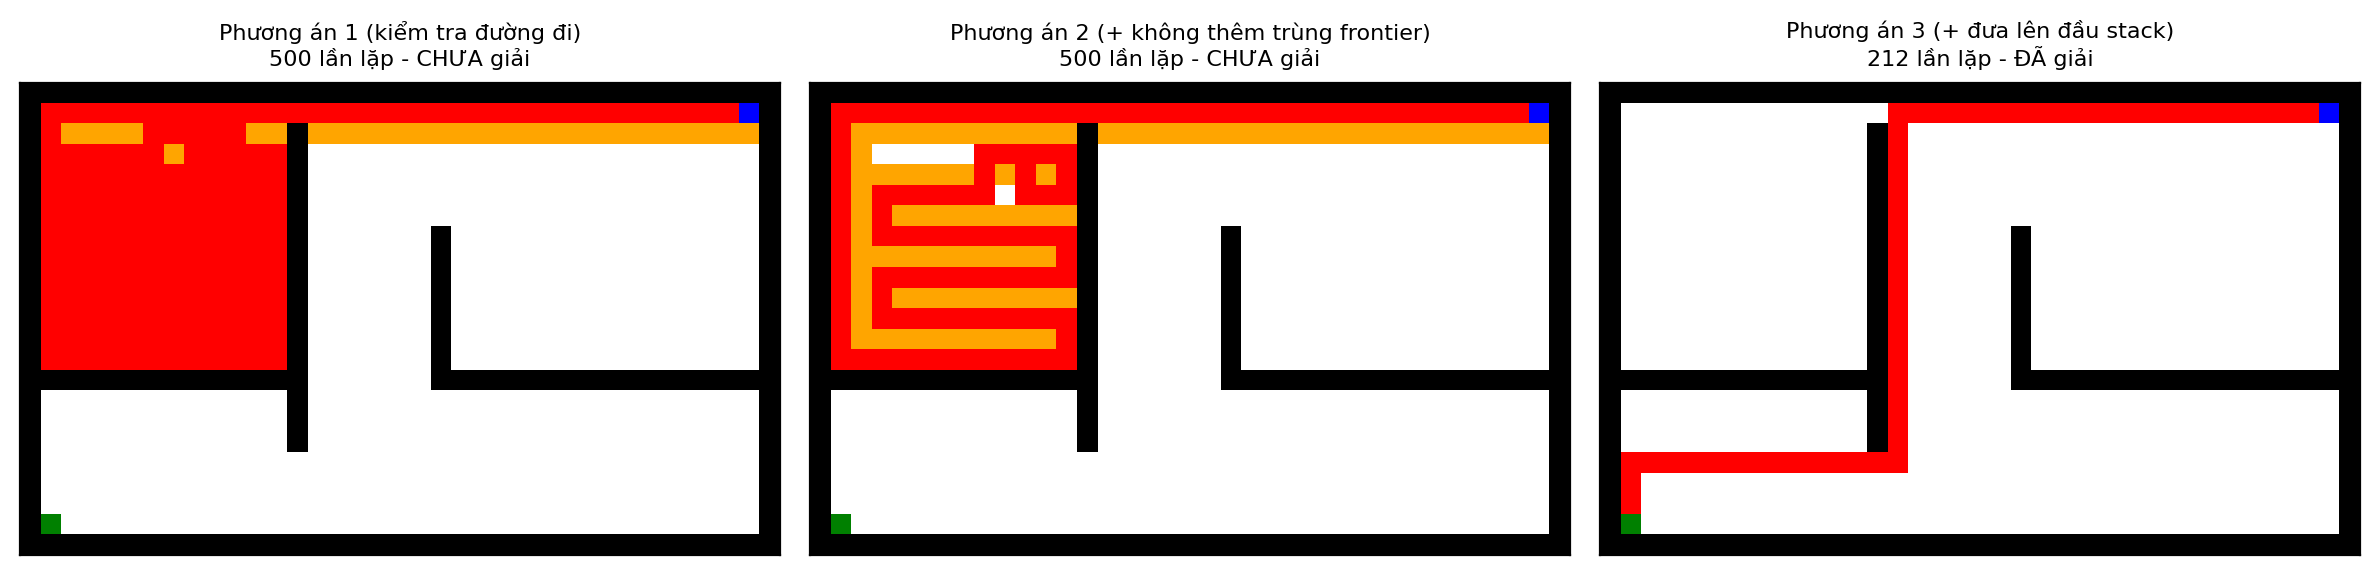

In [7]:
import matplotlib.pyplot as plt
from matplotlib import colors
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, opt in zip(ax, (3, 2, 1)):
    r = ts.DFS(maze, max_tries=500, frontier_option=opt, animation=True)
    m = r['maze_anim'][-1]
    code = {' ':0,'X':1,'S':2,'G':3,'P':4,'.':5,'F':6}
    v = np.vectorize(code.get)(m)
    a.imshow(v, cmap=colors.ListedColormap(['white','black','blue','green','red','gray','orange']), vmin=0, vmax=6)
    a.set_title(f"{names[opt]}\n{r['stats']['iterations']} lần lặp - {'ĐÃ giải' if r['stats']['solved'] else 'CHƯA giải'}", fontsize=8)
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### Thứ tự hướng ngẫu nhiên: 30 lần chạy, giới hạn 5.000 lần lặp
DFS rất nhạy với thứ tự sinh trạng thái con nên kiểm tra thêm độ ổn định của từng phương án.

In [8]:
rows = {}
for opt in (3, 2, 1):
    ss = []
    for seed in range(30):
        ts.set_order(random=True)
        ss.append(ts.DFS(maze, max_tries=5000, frontier_option=opt, rng=random.Random(seed))['stats'])
    ok = [s for s in ss if s['solved']]
    print(f"{names[opt]:42} giải được {len(ok):2d}/30 | lặp TB (các lần giải được) = {np.mean([s['iterations'] for s in ok]) if ok else float('nan'):7.1f}"
          f" | maxFr TB = {np.mean([s['max_frontier'] for s in ss]):6.1f} | mở rộng lại TB = {np.mean([s['reexpansions'] for s in ss]):7.1f}"
          f" | dài ĐĐ TB = {np.mean([s['path_len'] for s in ok]) if ok else float('nan'):6.1f}")
ts.set_order("NESW")

Phương án 1 (kiểm tra đường đi)            giải được  4/30 | lặp TB (các lần giải được) =  1693.5 | maxFr TB =  212.2 | mở rộng lại TB =  4360.4 | dài ĐĐ TB =  227.5


Phương án 2 (+ không thêm trùng frontier)  giải được  3/30 | lặp TB (các lần giải được) =   403.0 | maxFr TB =  119.1 | mở rộng lại TB =  4396.2 | dài ĐĐ TB =  127.3


Phương án 3 (+ đưa lên đầu stack)          giải được 30/30 | lặp TB (các lần giải được) =   435.6 | maxFr TB =   83.4 | mở rộng lại TB =     0.0 | dài ĐĐ TB =  200.5


## Kết luận Bài 7
| | Phương án 1 | Phương án 2 | Phương án 3 |
|---|---|---|---|
| Giải được (NESW, 500 lần lặp) | Không | Không | Có (212 lần lặp) |
| Max frontier | 155 | 91 | 64 |
| Mở rộng lại trạng thái | 321 | 383 | 0 |
| Mục trùng trong frontier | tối đa 17 | 0 | 0 |
| Giải được / 30 lần ngẫu nhiên | 4 | 3 | 30 |

* Chỉ kiểm tra chu trình trên **đường đi hiện tại** là chưa đủ: DFS không có bảng reached nên sau khi quay lui nó quên vùng đã duyệt và khám phá lại (số đường đi đơn giản trong căn phòng 13×13 tăng theo cấp số mũ).
* Phương án 2 làm frontier gọn hơn nhưng không sửa được gốc rễ vì mục cũ (đường đi cũ) vẫn nằm sâu trong stack.
* **Phương án 3** giữ cho mỗi trạng thái chỉ có một mục trong frontier và luôn ở đúng vị trí DFS, nên không lặp trạng thái, frontier nhỏ nhất và giải được ổn định. Chi phí: phải tìm và xóa mục cũ trong stack (O(|frontier|) nếu dùng danh sách) và kiểm tra đường đi O(độ sâu) cho mỗi nút.